In [2]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
from collections import OrderedDict
from datasets import load_dataset
from torch.utils.data import DataLoader
from scipy.sparse import csr_matrix
from sklearn.metrics import classification_report
import torch.nn as nn

import experiment
import clslib
import analysis
import mmlp

In [3]:
dataset = load_dataset("stanfordnlp/sst2")
# temp_train_df = dataset["train"].to_pandas()
# temp_val_df = dataset["validation"].to_pandas()
# dataset_df = pd.concat([temp_train_df, temp_val_df], ignore_index=True).drop(columns=['idx'])
# train_df, val_df, test_df = np.split(dataset_df, [int(0.8 * len(dataset_df)), int(0.9 * len(dataset_df))])

# train_dataset = Dataset.from_pandas(train_df)
# val_dataset = Dataset.from_pandas(val_df)
# test_dataset = Dataset.from_pandas(test_df)
train_dataset = dataset["train"]
test_dataset = dataset["validation"]

In [4]:
vocab_size = 1000
min_frequency = 2
my_seeds = [0]
num_folds = 5
my_cross_validation_sets = []
results_folder = Path("./results")
results_folder.mkdir(exist_ok=True)

for seed in my_seeds:
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(train_dataset["sentence"], train_dataset["label"])), 
            k=num_folds,
            seed=seed
        )
    )

bpe_tokenizer = experiment.train_bpe_tokenizer(train_dataset["sentence"], vocab_size, min_frequency)
# tokenizer.save(f"{results_folder}/BPE_tokenizer_vs_{vocab_size}_mf_{min_frequency}.json")

indicator_encoder = clslib.TokenIndicator(bpe_tokenizer)

my_classifiers = OrderedDict()

In [5]:
hidden_dim=128
hidden_dim_2=128
dropout=0.1
batch_size=64
learning_rate=1e-3
weight_decay=1e-4
num_epochs=10
device='cpu'

my_classifiers['modMLP_indic-enc'] = []

for run, seed in enumerate(my_seeds):
    run_folder = f"{results_folder}/modMLP_indic-enc/seed-{seed}"

    my_classifiers['modMLP_indic-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            encoder=indicator_encoder,
            model_option='mmlp',
            save_to=run_folder,
            mmlp_args={
                'hidden_dim': hidden_dim,
                'hidden_dim_2': hidden_dim_2,
                'dropout': dropout,
                'batch_size': batch_size,
                'learning_rate': learning_rate,
                'weight_decay': weight_decay,
                'num_epochs': num_epochs,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 111.807 seconds
Dataloader done! Time taken: 5.591 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

c:\Users\Alex\Documents\A Docs\Logic\Logic courses\NLP new\NLP-Assignment-1\mmlp.py:75: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.4854 | train acc: 0.7598 | val loss: 0.3860 | val acc: 0.8234
Epoch 02 | train loss: 0.3175 | train acc: 0.8648 | val loss: 0.3045 | val acc: 0.8731
Epoch 03 | train loss: 0.2212 | train acc: 0.9113 | val loss: 0.2677 | val acc: 0.8927
Epoch 04 | train loss: 0.1635 | train acc: 0.9361 | val loss: 0.2691 | val acc: 0.9010
Epoch 05 | train loss: 0.1286 | train acc: 0.9522 | val loss: 0.2680 | val acc: 0.9048
Epoch 06 | train loss: 0.1031 | train acc: 0.9622 | val loss: 0.2856 | val acc: 0.9056
Epoch 07 | train loss: 0.0868 | train acc: 0.9669 | val loss: 0.2992 | val acc: 0.9081
Epoch 08 | train loss: 0.0748 | train acc: 0.9719 | val loss: 0.3053 | val acc: 0.9102
Epoch 09 | train loss: 0.0659 | train acc: 0.9758 | val loss: 0.3200 | val acc: 0.9099
Epoch 10 | train loss: 0.0585 | train acc: 0.9782 | val loss: 0.3298 | val acc: 0.9109
Training done! Time taken: 229.649 seconds
Transforming documents...
Document transformation done! Time taken: 61.575 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4841 | train acc: 0.7586 | val loss: 0.3854 | val acc: 0.8276
Epoch 02 | train loss: 0.3078 | train acc: 0.8688 | val loss: 0.3081 | val acc: 0.8729
Epoch 03 | train loss: 0.2113 | train acc: 0.9169 | val loss: 0.2757 | val acc: 0.8927
Epoch 04 | train loss: 0.1569 | train acc: 0.9414 | val loss: 0.2770 | val acc: 0.8983
Epoch 05 | train loss: 0.1234 | train acc: 0.9537 | val loss: 0.2890 | val acc: 0.9030
Epoch 06 | train loss: 0.1011 | train acc: 0.9619 | val loss: 0.3014 | val acc: 0.9024
Epoch 07 | train loss: 0.0820 | train acc: 0.9704 | val loss: 0.3253 | val acc: 0.9065
Epoch 08 | train loss: 0.0736 | train acc: 0.9728 | val loss: 0.3305 | val acc: 0.9091
Epoch 09 | train loss: 0.0623 | train acc: 0.9773 | val loss: 0.3607 | val acc: 0.9076
Epoch 10 | train loss: 0.0560 | train acc: 0.9793 | val loss: 0.3678 | val acc: 0.9105
Training done! Time taken: 176.448 seconds
Transforming documents...
Document transformation done! Time taken: 66.669 seconds
Data

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.4846 | train acc: 0.7593 | val loss: 0.3846 | val acc: 0.8291
Epoch 02 | train loss: 0.3103 | train acc: 0.8673 | val loss: 0.3244 | val acc: 0.8649
Epoch 03 | train loss: 0.2139 | train acc: 0.9143 | val loss: 0.2893 | val acc: 0.8882
Epoch 04 | train loss: 0.1593 | train acc: 0.9398 | val loss: 0.2738 | val acc: 0.9007
Epoch 05 | train loss: 0.1257 | train acc: 0.9532 | val loss: 0.2782 | val acc: 0.9065
Epoch 06 | train loss: 0.1023 | train acc: 0.9619 | val loss: 0.2832 | val acc: 0.9050
Epoch 07 | train loss: 0.0851 | train acc: 0.9688 | val loss: 0.3048 | val acc: 0.9085
Epoch 08 | train loss: 0.0734 | train acc: 0.9728 | val loss: 0.3309 | val acc: 0.9102
Epoch 09 | train loss: 0.0640 | train acc: 0.9763 | val loss: 0.3340 | val acc: 0.9090
Epoch 10 | train loss: 0.0587 | train acc: 0.9790 | val loss: 0.3614 | val acc: 0.9096
Training done! Time taken: 247.470 seconds


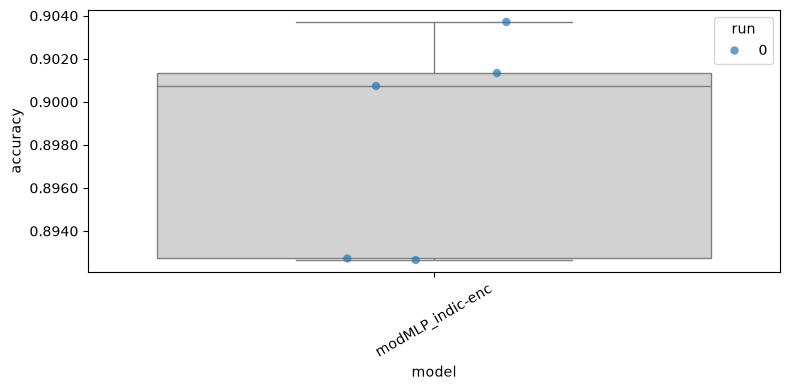

In [6]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [7]:
testing_sentences = test_dataset["sentence"]
testing_vectors = [indicator_encoder(text) for text in testing_sentences]
testing_labels = test_dataset["label"]
X_test_sparse = csr_matrix(testing_vectors)
test_dataset_sparse = mmlp.SparseDataset(X_test_sparse, testing_labels)

test_loader = DataLoader(
        test_dataset_sparse,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=mmlp.sparse_collate
    )

criterion = nn.BCEWithLogitsLoss()

for run, seed in enumerate(my_seeds):
    for fold in range(num_folds):    
        model_folder = f"{results_folder}/modMLP_indic-enc/seed-{seed}/fold-{fold}/model"
        model = mmlp.load(model_folder)

        mmlp.evaluate(model, test_loader, criterion, device)
        test_metrics, preds = mmlp.evaluate(model, test_loader, criterion, device)
        print(test_metrics)
        print(classification_report(testing_labels, preds))

{'loss': 0.6563845632273123, 'accuracy': 0.7660550458715596}
              precision    recall  f1-score   support

           0       0.76      0.76      0.76       428
           1       0.77      0.77      0.77       444

    accuracy                           0.77       872
   macro avg       0.77      0.77      0.77       872
weighted avg       0.77      0.77      0.77       872

{'loss': 0.8398347622757658, 'accuracy': 0.7488532110091743}
              precision    recall  f1-score   support

           0       0.77      0.70      0.73       428
           1       0.73      0.80      0.76       444

    accuracy                           0.75       872
   macro avg       0.75      0.75      0.75       872
weighted avg       0.75      0.75      0.75       872

{'loss': 0.7930091258582719, 'accuracy': 0.7637614678899083}
              precision    recall  f1-score   support

           0       0.78      0.72      0.75       428
           1       0.75      0.81      0.78       444


In [8]:
# save results
Path("metrics").mkdir(exist_ok=True)

df = analysis.make_data_frame(my_classifiers)
df["seed"] = df["run"].map(dict(enumerate(my_seeds)))

df.to_csv(f"metrics/{next(iter(my_classifiers))}.csv", index=False)